In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [3]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [4]:
df1_part3 = df_part3

idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)

In [5]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'

# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()
df_part3['month-year'] = [d.strftime('%b') + str(d.year) for d in df_part3.index]

# # df_part3['date']
years = df_part3['year'].unique()

# BOX PLOT

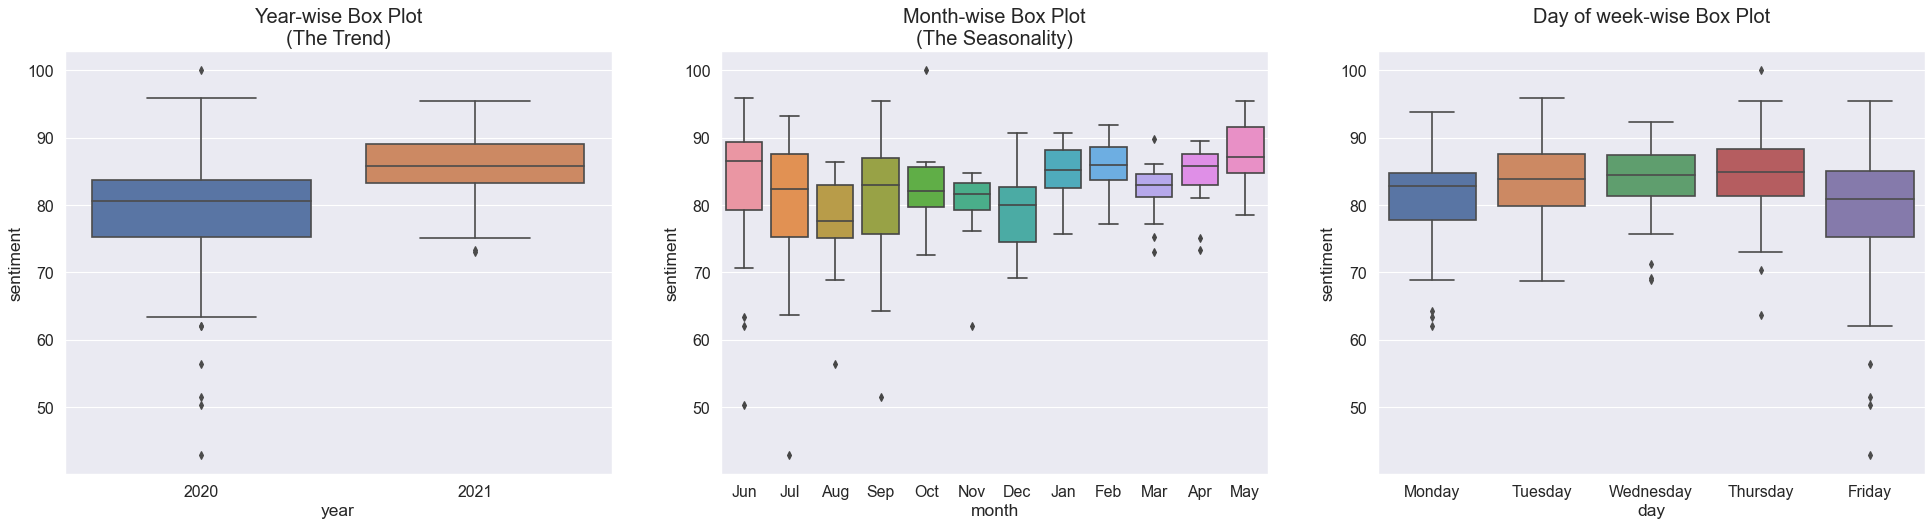

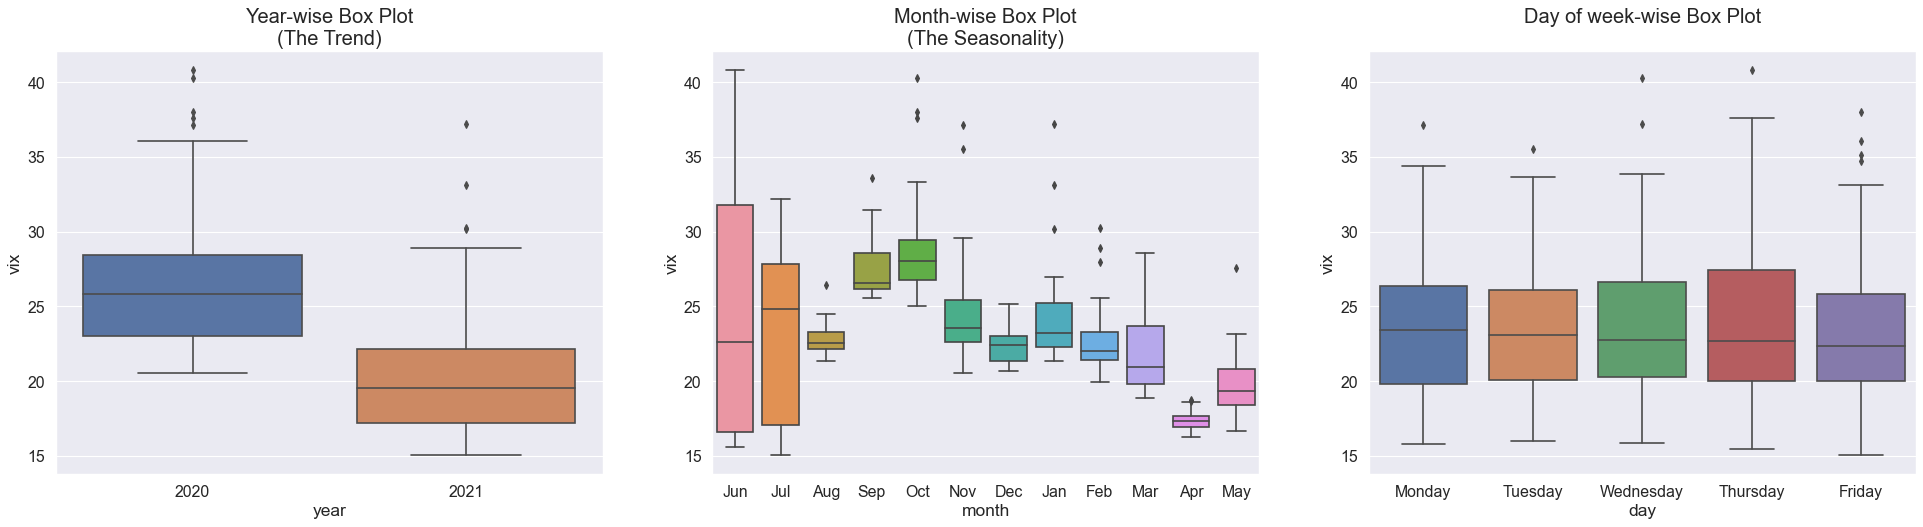

In [6]:
# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='sentiment', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='sentiment', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='sentiment', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='vix', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='vix', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='vix', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

In [7]:
# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 80)
sns.boxplot(x='month', y='vix',hue="year", data=df_part3, ax=axes[0])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='month', y='sentiment',hue="year", data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('VIX Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[1].set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)

plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_vix = sns.boxplot(x='month-year', y='vix', data=df_part3, ax=axes)# data=df.loc[~df.year.isin([1991, 2008]), :])
ax_vix = sns.swarmplot(x='month-year', y='vix', data=df_part3, color=".25")

# Set Title
axes.set_title('VIX Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_sentiment = sns.boxplot(x='month-year', y='sentiment', data=df_part3, ax=axes)# data=df.loc[~df.year.isin([1991, 2008]), :])
ax_sentiment = sns.swarmplot(x='month-year', y='sentiment', data=df_part3, color=".25")

# Set Title
axes.set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

# VIOLIN 

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 80)
sns.violinplot(x='year', y='vix', data=df_part3, ax=axes[0])
#sns.violinplot(x='month', y='vix', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.violinplot(x='day', y='vix', data=df_part3,hue='year', ax=axes[1], split=True)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
#axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[1].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 80)
sns.violinplot(x='year', y='sentiment', data=df_part3, ax=axes[0])
#sns.violinplot(x='month', y='vix', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.violinplot(x='day', y='sentiment', data=df_part3,hue='year', ax=axes[1], split=True)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
#axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[1].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 100)
sns.violinplot(x='month', y='vix',hue="year", data=df_part3, ax=axes[0],split=True)# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.violinplot(x='month', y='sentiment',hue="year", data=df_part3, ax=axes[1],split=True)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('VIX Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[1].set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)

plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 100)
sns.violinplot(x='month-year', y='vix', data=df_part3, ax=axes)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes.set_title('VIX Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 100)
sns.violinplot(x='month-year', y='sentiment', data=df_part3, ax=axes, jitter=True, zorder=1)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes.set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

# VIX ANALYSIS 2010 - 2021 

In [ ]:
# Import Data
df_vix_2010_2021=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_options=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_vix_2010_2021['Date']= pd.to_datetime(df_vix_2010_2021['Date'])
df_vix_2010_2021.index= df_vix_2010_2021['Date']
print("df_vix_2010_2021['Date']="+str(type(df_vix_2010_2021['Date'])))
print("df_part3['Date']="+str(type(df_part3['date'])))

df_vix_2010_2021["vix"] = df_vix_2010_2021["Adj Close"]#.apply(np.int)
df_vix_2010_2021["vix_ln_return"]=np.log(df_vix_2010_2021["vix"]/df_vix_2010_2021["vix"].shift(1))

import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()] 

df_vix_2010_2021['year'] = [d.year for d in df_vix_2010_2021.Date]
df_vix_2010_2021['month'] = [d.strftime('%b') for d in df_vix_2010_2021.Date]
df_vix_2010_2021['day'] = [d for d in df_vix_2010_2021.index.day_name()]
years = df_vix_2010_2021['year'].unique()
df_vix_2010_2021['month-year'] = [d.strftime('%b') + str(d.year) for d in df_vix_2010_2021.Date]

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 80)
sns.violinplot(x='year', y='vix', data=df_vix_2010_2021, ax=axes[0])
sns.violinplot(x='day', y='vix', data=df_vix_2010_2021,ax=axes[1])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
sns.violinplot(x='year', y='vix', data=df_vix_2010_2021.loc[~df_vix_2010_2021.year.isin(["2010", "2019"]), :], ax=axes)
axes.set_title('VIX Year-wise Box Plot\n(The Trend)', fontsize=18); 

plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20,7), dpi= 80)
sns.boxplot(x='year', y='vix', data=df_vix_2010_2021, ax=axes[0])
sns.boxplot(x='month', y='vix', data=df_vix_2010_2021.loc[~df_vix_2010_2021.year.isin(["2010", "2019"]), :])
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(30,15), dpi= 80)
sns.boxplot(x='day', y='Open', data=df_vix_2010_2021, ax=axes)
axes.set_title('Day of week-wise Box Plot\n', fontsize=18)
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(30,7), dpi= 80)
sns.violinplot(x='day', y='vix', data=df_vix_2010_2021.loc[~df_vix_2010_2021.year.isin([2010, 2019]), :], ax=axes[0])
axes[0].set_title('VIX ADJ CLOSE Day of week-wise Box Plot\n', fontsize=18)
sns.violinplot(x='day', y='Open', data=df_vix_2010_2021.loc[~df_vix_2010_2021.year.isin([2010, 2019]), :], ax=axes[1])
axes[1].set_title('VIX OPEN Day of week-wise Box Plot\n', fontsize=18)
plt.show()

# Hourly

In [ ]:
df_hourly_sentiment=pd.read_pickle("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/Articles_sentiment_hourly.pkl")


In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_sentiment = sns.boxplot(x='Hour', y='sentiment', data=df_hourly_sentiment, ax=axes)
# ax_sentiment = sns.swarmplot(x='Hour', y='sentiment', data=df_hourly_sentiment, color=".25")

# Set Title
axes.set_title('Sentiment Hourly', fontsize=18)
plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_sentiment = sns.boxplot(x='Hour', y='pos', data=df_hourly_sentiment, ax=axes)
# ax_sentiment = sns.swarmplot(x='Hour', y='sentiment', data=df_hourly_sentiment, color=".25")

# Set Title
axes.set_title('Positive Hourly Sentiment', fontsize=18)
plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_sentiment = sns.boxplot(x='Hour', y='neg', data=df_hourly_sentiment, ax=axes)
# ax_sentiment = sns.swarmplot(x='Hour', y='sentiment', data=df_hourly_sentiment, color=".25")

# Set Title
axes.set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 80)
ax_sentiment = sns.boxplot(x='Hour', y='neu', data=df_hourly_sentiment, ax=axes)
# ax_sentiment = sns.swarmplot(x='Hour', y='sentiment', data=df_hourly_sentiment, color=".25")

# Set Title
axes.set_title('Sentiment Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

In [ ]:
# Draw Plot
fig, axes = plt.subplots(1, 1, figsize=(20,7), dpi= 100)
df_hourly_sentiment.fillna(0, inplace=True)

sns.violinplot(x='Hour', y='sentiment', data=df_hourly_sentiment, ax=axes, jitter=True, zorder=1)# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes.set_title('Sentiment Hourly', fontsize=18)
plt.show()